In [1]:
!pip install fairlearn

# Task 1: Load and Clean Data, Train Logistic Regression Baseline Model

In [6]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# Load dataset
df = pd.read_csv('/content/adult.csv')

# Standard clean-up: Strip whitespace from object columns and replace '?' with NaN
for col in df.select_dtypes(include=['object']).columns:
    df[col] = df[col].astype(str).str.strip()
df = df.replace('?', np.nan).dropna()

# Define features and target (income >50K is 1, <=50K is 0)
y = df['income'].apply(lambda x: 1 if '>50K' in x else 0)

# Track the sensitive feature 'sex'
A = df['sex']

# Drop target and sensitive feature from X using the correct keyword 'columns'
X = df.drop(columns=['income', 'sex'], errors='ignore')

# Split data
X_train, X_test, y_train, y_test, A_train, A_test = train_test_split(
    X, y, A, test_size=0.3, random_state=42, stratify=y
)

# Define preprocessing
numeric_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = X.select_dtypes(include=['object']).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features)
    ]
)

# Create and train the model
baseline_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42))
])

baseline_model.fit(X_train, y_train)

y_pred_baseline = baseline_model.predict(X_test)

# Tasks 2 & 3: Compute Baseline Fairness Metrics

In [7]:
from sklearn.metrics import accuracy_score
from fairlearn.metrics import (
    MetricFrame,
    selection_rate,
    true_positive_rate,
    false_positive_rate,
    demographic_parity_difference,
    demographic_parity_ratio,
    equalized_odds_difference
)

# Define metric functions for MetricFrame
metrics = {
    'accuracy': accuracy_score,
    'selection_rate': selection_rate,
    'tpr': true_positive_rate,
    'fpr': false_positive_rate
}

# Compute metrics grouped by sex
frame_baseline = MetricFrame(
    metrics=metrics,
    y_true=y_test,
    y_pred=y_pred_baseline,
    sensitive_features=A_test
)

# Report baseline results
print(f"Baseline model: Logistic Regression Accuracy: {accuracy_score(y_test, y_pred_baseline):.2f}\n")
print("GROUP ACCURACY SELECTION_RATE TPR FPR")
print("---------------------------------------------------")
for group in ['Male', 'Female']:
    print(f"{group:<8} {frame_baseline.by_group.loc[group, 'accuracy']:.2f}     "
          f"{frame_baseline.by_group.loc[group, 'selection_rate']:.2f}           "
          f"{frame_baseline.by_group.loc[group, 'tpr']:.2f} {frame_baseline.by_group.loc[group, 'fpr']:.2f}")
print("---------------------------------------------------")

dp_diff = demographic_parity_difference(y_test, y_pred_baseline, sensitive_features=A_test)
dp_ratio = demographic_parity_ratio(y_test, y_pred_baseline, sensitive_features=A_test)
eo_diff = equalized_odds_difference(y_test, y_pred_baseline, sensitive_features=A_test)

print(f"Demographic parity difference: {dp_diff:.2f}")
print(f"Demographic parity ratio (DI): {dp_ratio:.2f} (< 0.80 -> BIAS)")
print(f"Equalized odds difference: {eo_diff:.2f}")


Baseline model: Logistic Regression Accuracy: 0.85

GROUP ACCURACY SELECTION_RATE TPR FPR
---------------------------------------------------
Male     0.82     0.26           0.62 0.09
Female   0.92     0.09           0.53 0.03
---------------------------------------------------
Demographic parity difference: 0.17
Demographic parity ratio (DI): 0.34 (< 0.80 -> BIAS)
Equalized odds difference: 0.08


# Tasks 4 & 5: Apply ThresholdOptimizer for Demographic Parity and Equalized Odds

In [8]:
from fairlearn.postprocessing import ThresholdOptimizer

# 1. Mitigation with Demographic Parity
to_dp = ThresholdOptimizer(
    estimator=baseline_model,
    constraints="demographic_parity",
    predict_method='predict_proba'
)
to_dp.fit(X_train, y_train, sensitive_features=A_train)
y_pred_dp = to_dp.predict(X_test, sensitive_features=A_test)

# 2. Mitigation with Equalized Odds
to_eo = ThresholdOptimizer(
    estimator=baseline_model,
    constraints="equalized_odds",
    predict_method='predict_proba'
)
to_eo.fit(X_train, y_train, sensitive_features=A_train)
y_pred_eo = to_eo.predict(X_test, sensitive_features=A_test)


# Task 6: Accuracy vs Fairness Comparison & Visualization

MODEL ACC SEL_M SEL_F DP_DIFF EO_DIFF
--------------------------------------------------------------
Baseline             0.85 0.26  0.09  0.17    0.08
TO: demographic_par. 0.83 0.18  0.17  0.00    0.29
TO: equalized_odds   0.84 0.23  0.13  0.09    0.02
--------------------------------------------------------------


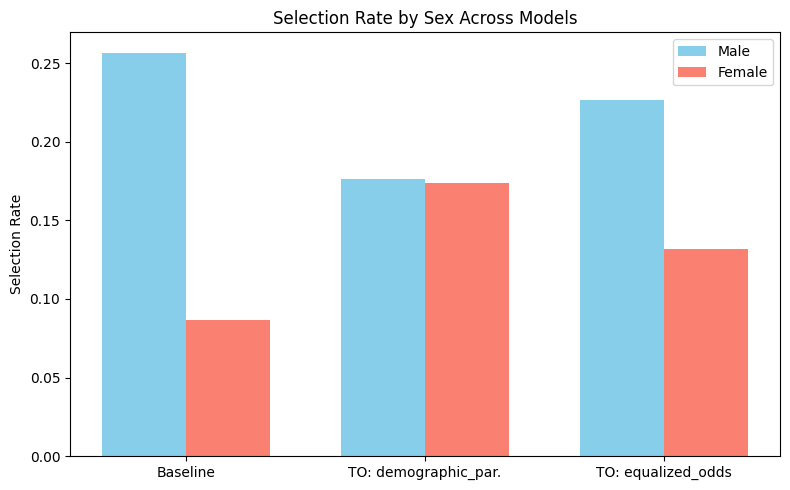

Plot saved: selection_rate_by_sex.png
No single model satisfies both fairness definitions.


In [9]:
import matplotlib.pyplot as plt

# Create metric frames for mitigated models to extract group specific rates easily
frame_dp = MetricFrame(metrics=metrics, y_true=y_test, y_pred=y_pred_dp, sensitive_features=A_test)
frame_eo = MetricFrame(metrics=metrics, y_true=y_test, y_pred=y_pred_eo, sensitive_features=A_test)

# Build comparative summary
summary_data = {
    'MODEL': ['Baseline', 'TO: demographic_par.', 'TO: equalized_odds'],
    'ACC': [
        accuracy_score(y_test, y_pred_baseline),
        accuracy_score(y_test, y_pred_dp),
        accuracy_score(y_test, y_pred_eo)
    ],
    'SEL_M': [
        frame_baseline.by_group.loc['Male', 'selection_rate'],
        frame_dp.by_group.loc['Male', 'selection_rate'],
        frame_eo.by_group.loc['Male', 'selection_rate']
    ],
    'SEL_F': [
        frame_baseline.by_group.loc['Female', 'selection_rate'],
        frame_dp.by_group.loc['Female', 'selection_rate'],
        frame_eo.by_group.loc['Female', 'selection_rate']
    ],
    'DP_DIFF': [
        demographic_parity_difference(y_test, y_pred_baseline, sensitive_features=A_test),
        demographic_parity_difference(y_test, y_pred_dp, sensitive_features=A_test),
        demographic_parity_difference(y_test, y_pred_eo, sensitive_features=A_test)
    ],
    'EO_DIFF': [
        equalized_odds_difference(y_test, y_pred_baseline, sensitive_features=A_test),
        equalized_odds_difference(y_test, y_pred_dp, sensitive_features=A_test),
        equalized_odds_difference(y_test, y_pred_eo, sensitive_features=A_test)
    ]
}

df_summary = pd.DataFrame(summary_data)

# Print requested comparative board layout
print("MODEL ACC SEL_M SEL_F DP_DIFF EO_DIFF")
print("--------------------------------------------------------------")
for _, row in df_summary.iterrows():
    print(f"{row['MODEL']:<20} {row['ACC']:.2f} {row['SEL_M']:.2f}  {row['SEL_F']:.2f}  {row['DP_DIFF']:.2f}    {row['EO_DIFF']:.2f}")
print("--------------------------------------------------------------")

# Plot selection rate by sex
x = np.arange(3)
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))
rects1 = ax.bar(x - width/2, df_summary['SEL_M'], width, label='Male', color='skyblue')
rects2 = ax.bar(x + width/2, df_summary['SEL_F'], width, label='Female', color='salmon')

ax.set_ylabel('Selection Rate')
ax.set_title('Selection Rate by Sex Across Models')
ax.set_xticks(x)
ax.set_xticklabels(df_summary['MODEL'])
ax.legend()

plt.tight_layout()
plt.savefig('selection_rate_by_sex.png')
plt.show()

print("Plot saved: selection_rate_by_sex.png")
print("No single model satisfies both fairness definitions.")
